# E11 -- Transmitted-bases decay vs. K_global

Measures the exponential decay of the per-round uplink as a function of the server dictionary size, with an exponential fit overlaid on a first-order theoretical bound.

* **Independent:** run this notebook top-to-bottom in a fresh kernel; it needs no other notebook's in-memory state.
* **Needs:** datasets.
* **Writes:** `results/experiment_11/exp11_decay_vs_kglobal.csv` and figures.
* **Shared code:** imported from the `fsibs` package (see `README.md`); everything experiment-specific is in this notebook.

In [1]:
# ============================================================
# F-SIBS MODULAR - PROJECT LOCATION + IMPORTS
# ============================================================

import sys,time, os
from pathlib import Path

# ------------------------------------------------------------
# Project location
# ------------------------------------------------------------

PROJECT_ROOT = Path("/home/ahmed_omara/F_SIBS_Modular").resolve()
PACKAGE_ROOT = PROJECT_ROOT / "fsibs"

# Validate project root
if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"\nF-SIBS project directory was not found:\n"
        f"  {PROJECT_ROOT}"
    )

# Validate fsibs package
if not PACKAGE_ROOT.exists():
    raise FileNotFoundError(
        f"\nF-SIBS package directory was not found:\n"
        f"  {PACKAGE_ROOT}\n\n"
        f"Project contents:\n"
        + "\n".join(f"  {p.name}" for p in PROJECT_ROOT.iterdir())
    )

if not (PACKAGE_ROOT / "__init__.py").exists():
    raise FileNotFoundError(
        f"\nF-SIBS package exists, but __init__.py was not found:\n"
        f"  {PACKAGE_ROOT / '__init__.py'}"
    )

# Add project root to Python import path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Use F-SIBS project as working directory
import os
os.chdir(PROJECT_ROOT)

# ------------------------------------------------------------
# Standard imports
# ------------------------------------------------------------

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fsibs.datasets import build_data_bundle
from fsibs.env import setup_environment
from fsibs.io_utils import save_figure, save_table
from fsibs.parallel import describe
from fsibs.runtime import init_run, new_manifest, save_manifest
from fsibs.selection import prompt_selection, resolve_selection

NOTE: this scikit-image has no MS-SSIM -> falls back to SSIM
NOTE: `imagecodecs` is not installed -- JPEG-LS will run in MOCKED mode (raw 8bpp passthrough). Install with `pip install imagecodecs` for the genuine CharLS-backed codec.


## Configuration
All settings of this experiment.

In [2]:
# ------------------------------------------------------------------------------------
# EXPERIMENT CONFIGURATION -- everything that can differ between experiments lives HERE,
# in this notebook.  Edit freely; no other notebook or module is affected.
# ------------------------------------------------------------------------------------
RUN_DIR_POLICY = "latest"      # "latest": re-use the newest F_SIBS_r_<date>_<n> folder (shared with the other
                               #   notebooks) | "new": start a fresh run folder | or an explicit folder path
INTERACTIVE_SELECTION = False  # True: ask for datasets / algorithms with the original input() menus

# Datasets: any of "coil20", "coil100", "eth80", "epfl", "dino", "temple"
SELECTED_DATASETS = ["coil20", "dino", "temple"]
# Algorithms: SIBSk and F-SIBS_k must be selected together (pairing rule); all other baselines are free
SELECTED_ALGORITHMS = [
    "OMP",
    "SIBS1",
    "F-SIBS_1",
    "SIBS2",
    "F-SIBS_2",
    "SIBS3",
    "F-SIBS_3",
    "SIBS4",
    "F-SIBS_4",
]

# ---- shared evaluation-protocol values (defaults from fsibs.protocol; override here for THIS experiment only) ----
from fsibs import protocol as P
RNG_SEED = P.RNG_SEED
COIL_VIEWS = P.COIL_VIEWS
COIL100_VIEWS = P.COIL100_VIEWS
ETH80_VIEWS = P.ETH80_VIEWS
COIL100_MAX_OBJECTS = P.COIL100_MAX_OBJECTS
ETH80_MAX_OBJECTS_PER_CAT = P.ETH80_MAX_OBJECTS_PER_CAT
EPFL_MAX_FRAMES = P.EPFL_MAX_FRAMES
EPFL_TARGET_HW = P.EPFL_TARGET_HW
COIL_N_CROSS_GROUPS = P.COIL_N_CROSS_GROUPS
K_VALUES = P.K_VALUES
DELTA = P.DELTA
K_SUMMARY = P.K_SUMMARY
N_ROUNDS_FULL = P.N_ROUNDS_FULL
EPS_CONV = P.EPS_CONV

## Setup
Run folder, selection and (when needed) datasets.

In [3]:
setup_environment(RNG_SEED)                       # warnings, global seed, Matplotlib defaults
describe()                                       # CPU / platform banner
run = init_run(RUN_DIR_POLICY)                    # resolves F_SIBS_r_<date>_<n> and creates its folders
RUN_DIR, FIG_DIR, RESULTS_DIR, DATA_DIR = run.RUN_DIR, run.FIG_DIR, run.RESULTS_DIR, run.DATA_DIR
EXPERIMENT_MANIFEST = new_manifest()              # files this notebook registers as outputs
print("RUN_DIR     :", RUN_DIR)
print("DATA_DIR    :", DATA_DIR)

# ---- algorithm / dataset selection (enforces the SIBSk <-> F-SIBS_k pairing rule) ----
if INTERACTIVE_SELECTION:
    SELECTED_DATASETS, SELECTED_ALGORITHMS = prompt_selection()
sel = resolve_selection(SELECTED_DATASETS, SELECTED_ALGORITHMS)
SELECTED_DATASETS, SELECTED_ALGORITHMS = sel.SELECTED_DATASETS, sel.SELECTED_ALGORITHMS
ACTIVE_F_SIBS_VARIANTS = sel.ACTIVE_F_SIBS_VARIANTS

# ---- datasets: acquisition (cached in DATA_DIR), node pools, federated groups ----
data = build_data_bundle(
    SELECTED_DATASETS, DATA_DIR,
    coil_views=COIL_VIEWS, coil100_views=COIL100_VIEWS, eth80_views=ETH80_VIEWS,
    coil100_max_objects=COIL100_MAX_OBJECTS, eth80_max_objects_per_cat=ETH80_MAX_OBJECTS_PER_CAT,
    epfl_max_frames=EPFL_MAX_FRAMES, epfl_target_hw=EPFL_TARGET_HW,
    coil_n_cross_groups=COIL_N_CROSS_GROUPS)
POOLS, PHI, GROUPS, CONV_SPECS = data.POOLS, data.PHI, data.GROUPS, data.CONV_SPECS

effective_cpu_count() = 96 | platform = Linux | MULTIPROCESSING_AVAILABLE = True
RUN_DIR     : /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1
DATA_DIR    : /home/ahmed_omara/F_SIBS_Modular/fsibs_data
EXPERIMENT CONFIGURATION

Selected datasets:
    COIL-20
    Middlebury Dino
    Middlebury Temple

Selected SIBS <-> F-SIBS pairs:
    SIBS1  + F-SIBS_1 
    SIBS2  + F-SIBS_2 
    SIBS3  + F-SIBS_3 
    SIBS4  + F-SIBS_4 

Selected other baselines:
    OMP

Final algorithms (SELECTED_METHODS):
    OMP
    SIBS1
    F-SIBS_1
    SIBS2
    F-SIBS_2
    SIBS3
    F-SIBS_3
    SIBS4
    F-SIBS_4
Configuration valid -- proceeding with the experiment campaign.
Active local SIBS methods (from SELECTED_BASELINES / SELECTED_SIBS_VARIANTS): ['SIBS1', 'SIBS2', 'SIBS3', 'SIBS4']
Active F-SIBS variants (from the user's paired SIBSk<->F-SIBS_k selection): ['F-SIBS_1', 'F-SIBS_2', 'F-SIBS_3', 'F-SIBS_4']


Middlebury datasets: 100% complete |██████████| 2/2 [00:00<00:00]


COIL-20 images: 1440 files in /home/ahmed_omara/F_SIBS_Modular/fsibs_data/Image_Classfiation_Coil20-master/dataset
dino    images: 16 PNGs in /home/ahmed_omara/F_SIBS_Modular/fsibs_data/dinoSparseRing
temple  images: 16 PNGs in /home/ahmed_omara/F_SIBS_Modular/fsibs_data/templeSparseRing
COIL-100: not selected -> acquisition skipped
ETH-80: not selected -> acquisition skipped
EPFL: not selected -> acquisition skipped


COIL-20 objects: 100% complete |██████████| 20/20 [00:00<00:00]
dino frames: 100% complete |██████████| 16/16 [00:00<00:00]
temple frames: 100% complete |██████████| 16/16 [00:00<00:00]

Node catalogue (one view of one object per node):
dataset  nodes  subjects  img_shape
 coil20     80        20 (128, 128)
   dino     16         1  (96, 128)
 temple     16         1  (96, 128)

federated node groups:
  coil20_same_object      20 groups | 4 members each
  coil20_cross_object      5 groups | 4 members each
  dino_ring                1 groups | 16 members each
  temple_ring              1 groups | 16 members each

NODE_CATALOG built: 112 rows across 3 datasets


## Experiment

E11: transmitted-bases decay vs. K_global on dino / dino_ring (variant F-SIBS_1, tau=0.95)

E11 -- exponential decay of transmitted bases vs. K_global:
 K_global  n_bases_transmitted_total  fit_lambda_per_round  theory_lambda_per_round
        8                        621                0.0912                   5.5053
       16                        712                0.1247                   5.5053
       32                        871                0.0750                   5.5053


K_global,n_bases_transmitted_total,fit_lambda_per_round,theory_lambda_per_round
8,621,0.09116,5.505
16,712,0.1247,5.505
32,871,0.07502,5.505


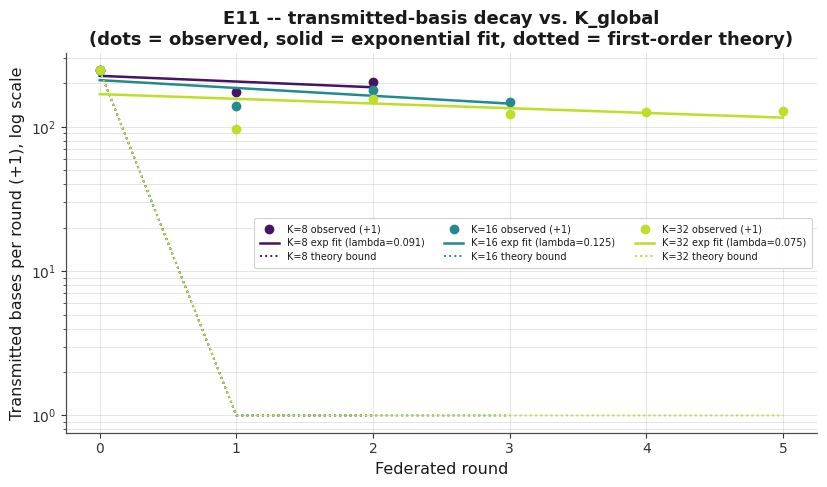

In [4]:
# ============================================================
# EXPERIMENT 11 (NEW) - Transmitted-Bases Decay vs. K_global
# ------------------------------------------------------------
# OBJECTIVE: measure the exponential decay of the per-round uplink
#   (transmitted bases) as a function of the server dictionary size
#   K_global, with an exponential fit overlaid on a first-order
#   theoretical bound.
# INPUTS: CONV_SPECS/GROUPS/POOLS/PHI (Cell 3), f_sibs_simulate with
#   return_transmitted_vectors=True (Cell 2), K_VALUES (Cell 1).
# OUTPUTS: results/experiment_11/exp11_decay_vs_kglobal.csv +
#   manifest self-registration.
# FIGURES: exp11_decay_semilog.png (semi-log decay: observed, fit,
#   theory, per K_global).
# TABLES: K_global x {#bases, fit lambda, theory lambda}.
# INTRODUCTION CONTRIBUTION: communication-scaling analysis.
# ============================================================
# ============================================================
# EXPERIMENT 11 (NEW) - how the novelty-filter uplink decays over rounds
# as a function of the server dictionary size K_global.
#
# For each K_global in K_VALUES the federation is run with
# return_transmitted_vectors metering (unchanged simulator); the
# per-round transmitted-basis counts are fitted with an exponential decay
# (semi-log linear least squares, lambda per round) and compared against
# the first-order theoretical bound
#     E[novel_r] <= C_r * (1 - tau^2)^(M_{r-1}),
# where C_r is the round-r candidate count and M_{r-1} the cumulative
# dictionary size after round r-1 (solid-angle argument for random unit
# bases vs. tau-caps around M existing atoms). The bound is a DESCRIPTIVE
# reference -- it assumes statistically independent random candidates,
# which real SIBS bases violate (they are shared across neighbouring
# columns), so the fit and the bound are reported side by side.
# ============================================================
try:
    if "CONV_SPECS" in globals() and CONV_SPECS and ACTIVE_F_SIBS_VARIANTS:
        _ds11, _cfg11, _gi11 = CONV_SPECS[0]
        _g11 = GROUPS[_cfg11][_gi11]
        _imgs11 = [POOLS[_ds11][i]["img"] for i in _g11["node_idx"]]
        _Phi11 = PHI[_ds11]
        _vname11, _vfn11 = next(iter(ACTIVE_F_SIBS_VARIANTS.items()))
        print("E11: transmitted-bases decay vs. K_global on %s / %s "
              "(variant %s, tau=0.95)" % (_ds11, _cfg11, _vname11))

        E11_ROWS = {}
        for _K11 in K_VALUES:
            _res11 = _vfn11(_imgs11, _Phi11, DELTA, K_SUMMARY, K_global=_K11,
                            n_rounds=N_ROUNDS_FULL, tau=0.95, eps_conv=EPS_CONV,
                            seed=42, return_transmitted_vectors=True)
            _tr11 = np.asarray(_res11["transmitted_bases_history"], dtype=float)
            _ca11 = np.asarray(_res11["candidate_bases_history"], dtype=float)
            E11_ROWS[_K11] = {"transmitted": _tr11, "candidates": _ca11,
                              "total_bases": int(_tr11.sum())}

        # ---- fit + theory per K_global ------------------------------------
        _tab11 = []
        for _K11, _d11 in E11_ROWS.items():
            _tr = _d11["transmitted"]; _ca = _d11["candidates"]
            _x = np.arange(len(_tr), dtype=float)
            _y = np.log10(_tr + 1.0)
            _A = np.vstack([_x, np.ones_like(_x)]).T
            _c, *_ = np.linalg.lstsq(_A, _y, rcond=None)
            _lam_fit = -_c[0] / np.log10(np.e)
            _M_prev, _theory = 0.0, []
            for _r in range(len(_tr)):
                _theory.append(_ca[_r] * ((1.0 - 0.95 ** 2) ** max(_M_prev, 0.0)))
                _M_prev += _tr[_r]
            _theory = np.asarray(_theory, dtype=float)
            _ok = _theory > 0
            _lam_theory = float("nan")
            if _ok.sum() >= 2:
                _yt = np.log10(_theory[_ok] + 1.0)
                _At = np.vstack([_x[_ok], np.ones_like(_x[_ok])]).T
                _ct, *_ = np.linalg.lstsq(_At, _yt, rcond=None)
                _lam_theory = -_ct[0] / np.log10(np.e)
            _tab11.append({"K_global": _K11, "n_bases_transmitted_total": _d11["total_bases"],
                           "fit_lambda_per_round": _lam_fit,
                           "theory_lambda_per_round": _lam_theory})
        E11_DF = pd.DataFrame(_tab11)
        print("\nE11 -- exponential decay of transmitted bases vs. K_global:")
        print(E11_DF.round(4).to_string(index=False))
        save_table(E11_DF, 11, "exp11_decay_vs_kglobal")
        EXPERIMENT_MANIFEST[11]["tables"].append("exp11_decay_vs_kglobal.csv")

        # ---- FIGURE: semi-log decay with fit + theory ----------------------
        fig, ax = plt.subplots(figsize=(8.4, 5), constrained_layout=True)
        _cmap11 = plt.cm.viridis(np.linspace(0.05, 0.9, len(E11_ROWS)))
        for _ci11, (_K11, _d11) in enumerate(sorted(E11_ROWS.items())):
            _tr = _d11["transmitted"] + 1.0
            _ca = _d11["candidates"]
            _x = np.arange(len(_d11["transmitted"]), dtype=float)
            _M_prev, _theory = 0.0, []
            for _r in range(len(_d11["transmitted"])):
                _theory.append(_ca[_r] * ((1.0 - 0.95 ** 2) ** max(_M_prev, 0.0)))
                _M_prev += _d11["transmitted"][_r]
            _row11 = E11_DF[E11_DF["K_global"] == _K11].iloc[0]
            ax.semilogy(_x, _tr, "o", ms=6, color=_cmap11[_ci11],
                        label="K=%d observed (+1)" % _K11)
            _y = np.log10(_tr)
            _A = np.vstack([_x, np.ones_like(_x)]).T
            _c, *_ = np.linalg.lstsq(_A, _y, rcond=None)
            ax.semilogy(_x, 10 ** (_c[0] * _x + _c[1]), "-", lw=1.8, color=_cmap11[_ci11],
                        label="K=%d exp fit (lambda=%.3f)" % (_K11, _row11["fit_lambda_per_round"]))
            ax.semilogy(_x, np.asarray(_theory) + 1.0, ":", lw=1.4, color=_cmap11[_ci11],
                        label="K=%d theory bound" % _K11)
        ax.set_xlabel("Federated round")
        ax.set_ylabel("Transmitted bases per round (+1), log scale")
        ax.set_title("E11 -- transmitted-basis decay vs. K_global\n"
                     "(dots = observed, solid = exponential fit, dotted = first-order theory)")
        ax.legend(fontsize=7, ncol=3); ax.grid(True, which="both", alpha=0.3)
        plt.tight_layout()
        save_figure(fig, 11, "exp11_decay_semilog")
        plt.show()
        EXPERIMENT_MANIFEST[11]["figures"].append("exp11_decay_semilog.png")
    else:
        print("Skipped: Experiment 11 (decay vs. K_global) -- no federated node "
              "group is available in this run.")
except Exception as e:
    print("Experiment 11 could not be computed:", repr(e))
    print("Requires CONV_SPECS, GROUPS, POOLS, PHI, ACTIVE_F_SIBS_VARIANTS, "
          "f_sibs_simulate(return_transmitted_vectors=True), K_VALUES from Cells 1-3.")


# ## Experiment E12 — Denoiser Ablation
# 
# **Objective.** Test whether a cheap, fixed-parameter, non-deep-learning denoiser applied
# before F-SIBS improves the entropy-coded rate-distortion trade-off, relative to the
# undenoised pipeline.
# 
# **Inputs:** `DENOISER_REGISTRY` (Cell 2 §2.7), `EXP_DENOISE_*` knobs (Cell 1), the
# unchanged F-SIBS pipeline. **Outputs:** per-(dataset, denoiser, run) R-D records over
# `K_SWEEP` with entropy coding; per-dataset comparison vs. baseline; overall ranking.
# 
# **Figures:** per-denoiser R-D curves (SSIM/PSNR/NMSE), time breakdown, overall ranking
# bar. **Tables:** raw runs, R-D curve by dataset/denoiser/k, summary, comparison, ranking.
# **Contribution supported:** practical pre-processing guidance for federated sparse coding.

## Register outputs

In [5]:
save_manifest(EXPERIMENT_MANIFEST, "E11")   # lets the F2 report notebook map this notebook's outputs

'/home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/manifests/E11.json'